# SN candidates from Lasair, cross-checked with ALeRCE

This notebook is self-contained. It goes from a Lasair query to a ranked list of SN candidates for the host-matching
step:

1. **Lasair**: select the objects (Sherlock classification + TNS) and get their host context.
2. **ALeRCE**: download everything we need for those objects (classification probabilities, Rubin detections,
   forced photometry, Gaia/WISE cross-matches).
3. **Compare the two brokers**, and understand why they disagree.
4. **Features → vetoes → SN score → tiers**: remove what is certainly *not* a SN, and rank the rest.
5. **Export** `sn_candidates_ranked.csv`.

All network queries are done in sections 1 and 2; everything after that works on the downloaded tables.

## 0. Setup

In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyvo
from alerce.core import Alerce
from lasair import lasair_client as lasair
from astropy.cosmology import Planck18

pd.set_option("display.max_colwidth", 1000)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)

### Configuration
The sample is defined here.

* `SHERLOCK_CLASS`: the Sherlock classification (context classifier of Lasair).
* `TNS_TYPE_CONDITION`: an SQL condition on the TNS classification (`crossmatch_tns.type`). Notes:
  * `None` drops the TNS condition, which gives all Sherlock "SN" **candidates**, most of them not spectroscopically
    classified. There are ~180 000 of them, so `LIMIT` matters.
* `LIMIT`: maximum number of objects returned by Lasair.

In [24]:
SHERLOCK_CLASS = "SN"
TNS_TYPE_CONDITION = "crossmatch_tns.type LIKE 'SN%'"   # every spectroscopic SN subtype
LIMIT = 1000

# Lasair API token: https://lasair.lsst.ac.uk/ -> My profile
LASAIR_TOKEN = os.getenv("LASAIR_LSST_TOKEN") or os.getenv("LASAIR_TOKEN")
if LASAIR_TOKEN is None:
    print("No Lasair token found: set LASAIR_LSST_TOKEN (or LASAIR_TOKEN) and restart the kernel.")

---
## 1. Lasair: selecting the objects

### Some information about Lasair
Lasair attaches a **Sherlock** classification to every object. Sherlock classifies transients **by location only**.
It does not look at the image or the light curve. It takes the transient RA and Dec, crossmatches them against
many catalogues (galaxies, stars, AGN, ...) and decides what the nearby source is based on its type, magnitude and
distance. **Typically**, an alert is classified as "SN" just because it is near a galaxy but offset from its
centre.

The query below selects the objects (Sherlock + TNS conditions). In the same query it also gets the Sherlock
host context that we use later:
* `separationArcsec`: distance between the transient and the **centre** of the associated galaxy.
* `physical_separation_kpc`, `z` (spectroscopic) and `photoZ`: the host redshift, when known.
* `catalogue_table_name` / `catalogue_object_type`: the catalogue(s) where the host was found.
* TNS name, prefix (`SN` = classified, `AT` = not yet) and type.

In [25]:
L = lasair(LASAIR_TOKEN, endpoint="https://api.lasair.lsst.ac.uk/api")

selected = """
    objects.diaObjectId,
    objects.ra,
    objects.decl,
    objects.absMag,
    objects.nDiaSources,
    objects.tns_name,
    crossmatch_tns.tns_prefix,
    crossmatch_tns.type AS tns_type,
    sherlock_classifications.classification,
    sherlock_classifications.catalogue_object_id,
    sherlock_classifications.catalogue_table_name,
    sherlock_classifications.catalogue_object_type,
    sherlock_classifications.separationArcsec,
    sherlock_classifications.physical_separation_kpc,
    sherlock_classifications.z,
    sherlock_classifications.photoZ,
    sherlock_classifications.Mag
"""
tables = "objects, sherlock_classifications" + (", crossmatch_tns" if TNS_TYPE_CONDITION else "")
conditions = f'sherlock_classifications.classification = "{SHERLOCK_CLASS}"'
if TNS_TYPE_CONDITION:
    conditions += f" AND {TNS_TYPE_CONDITION}"
else:
    # without crossmatch_tns in the tables, these columns don't exist
    selected = selected.replace("crossmatch_tns.tns_prefix,", "").replace("crossmatch_tns.type AS tns_type,", "")
conditions += " ORDER BY objects.diaObjectId"     # reproducible selection when LIMIT cuts the list

results = L.query(selected, tables, conditions, limit=LIMIT)
df_lasair = pd.DataFrame(results).drop_duplicates(subset=["diaObjectId"])
df_lasair["oid"] = df_lasair["diaObjectId"].astype(str)
df_lasair = df_lasair.set_index("oid")

print(len(df_lasair), "objects selected in Lasair")
df_lasair.head()

187 objects selected in Lasair


,diaObjectId,ra,decl,absMag,nDiaSources,tns_name,tns_prefix,tns_type,classification,catalogue_object_id,catalogue_table_name,catalogue_object_type,separationArcsec,physical_separation_kpc,z,photoZ,Mag
oid,,,,,,,,,,,,,,,,,
170019717277810735,170019717277810735,151.740280,1.927048,NaN,754,2026ctw,SN,SN Ia,SN,"10000,342494,11570",DESI,galaxy,0.200,NaN,NaN,NaN,24.019
170028486191218743,170028486191218743,64.185358,-48.943241,NaN,88,2026qrh,SN,SN Ia,SN,"10000,81273,866",DESI/2MASS,galaxy,0.129,NaN,NaN,NaN,17.776
170028500610711681,170028500610711681,150.746080,2.336469,NaN,165,2024xom,SN,SN Ia,SN,CGCG036-024,NED/DESI,galaxy,23.615,20.532,0.044167,NaN,14.212
170028510695916335,170028510695916335,151.592581,1.158332,NaN,273,2025mbp,SN,SN Ia,SN,2MASXJ10062208+0109317,NED/SDSS/PS1/DESI/2MASS,galaxy,2.734,2.478,0.046159,0.098590,17.350
170028521695477812,170028521695477812,151.317652,2.395209,-16.7277,693,2025aluu,SN,SN II,SN,2MASXJ10051617+0223390,NED/SDSS/DESI/PS1/2MASS,galaxy,2.952,5.121,0.093364,0.089088,16.210


---
## 2. ALeRCE: downloading everything for these objects

### Some information about ALeRCE
ALeRCE classifies with machine learning. Its **stamp classifier** looks at the image cut-outs of an alert
(science, template, difference) and returns a probability for each of five classes: SN, AGN, VS (variable star),
asteroid and bogus. The most likely class gets `ranking = 1`. A SN is typically seen as a clean point in the
difference image, offset from a galaxy in the template.

Another important point: in ALeRCE (and other brokers) an `oid` is an **object**, i.e. a position in the sky, and
many alerts (detections) can belong to the same `oid`. This helps us decide whether an alert is really a bogus:
something seen once or twice may be a bogus, but something that keeps appearing at the same place is real.
For example, ML struggles with bright galaxies: after the image subtraction some spiral arms may remain, and the
classifier calls the alert bogus, but it might be a SN or an AGN.

We use the ALeRCE **TAP** service (SQL over the ALeRCE database). Its useful tables:

| Table | Content |
|---|---|
| `object` | one row per object: mean position, first/last detection, `n_det`, ... |
| `probability` + `taxonomy` | classifier probabilities and class names (`classifier_id = 3` = `stamp_classifier_rubin_beta_20260421`) |
| `detection` + `lsst_detection` | every alert, with the full Rubin `diaSource` record |
| `forced_photometry` + `lsst_forced_photometry` | flux measured at the object position in every later visit |
| `xmatch` + `gaiadr3_source` / `allwise` | cross-matches with Gaia DR3 (`catid = 1`) and AllWISE (`catid = 0`) |

`sid = 1` selects LSST diaObjects.

In [26]:
alerce = Alerce()
tap_service = pyvo.dal.TAPService("https://tap.alerce.online/tap")

def tap(query):
    """Run an ADQL query on the ALeRCE TAP service and return a DataFrame with `oid` as string."""
    df = tap_service.search(query, maxrec=5_000_000).to_table().to_pandas()
    if "oid" in df:
        df["oid"] = df["oid"].astype(str)
    return df

# list of Lasair diaObjectIds for the ADQL IN (...) clauses
ids_sql = ",".join(f"'{x}'" for x in df_lasair.index)

### 2.1 Objects and stamp-classifier probabilities
`probability` has one row per (object, class). We keep **all five** probabilities, not only the most likely class:
an object called "bogus" with p = 0.6 can have SN as its second choice.

In [27]:
obj = tap(f"""
SELECT oid, meanra, meandec, firstmjd, lastmjd, deltamjd, n_det, n_forced
FROM alerce_tap.object
WHERE sid = 1 AND oid IN ({ids_sql})
""").drop_duplicates("oid").set_index("oid")

prob = tap(f"""
SELECT prob.oid, tax.class_name, prob.probability, prob.ranking
FROM alerce_tap.probability AS prob
JOIN alerce_tap.taxonomy AS tax
    ON prob.classifier_id = tax.classifier_id AND prob.class_id = tax.class_id
WHERE prob.sid = 1 AND prob.classifier_id = 3
  AND prob.oid IN ({ids_sql})
""")

print(len(obj), "of", len(df_lasair), "objects found in ALeRCE")

187 of 187 objects found in ALeRCE


### 2.2 Detections (alerts)
`detection` only has time, band and position; `lsst_detection` has the full Rubin `diaSource` record. We join both
by `measurement_id` and keep the columns used later:

| Column | Meaning |
|---|---|
| `psfflux`, `psffluxerr`, `snr` | flux in the difference image (nJy) and its significance |
| `isnegative` | the source is **fainter** than in the template (negative difference flux) |
| `reliability` | Rubin's own real/bogus ML score (0 = bogus, 1 = real), computed for every detection |
| `extendedness` | 0 = point-like, 1 = extended in the difference image |
| `isdipole` | positive and negative lobes next to each other (misaligned subtraction) |

In [28]:
det = tap(f"""
SELECT d.oid, d.mjd, d.band, d.ra, d.dec,
       l.psfflux, l.psffluxerr, l.snr, l.isnegative, l.reliability,
       l.extendedness, l.isdipole
FROM alerce_tap.detection AS d
JOIN alerce_tap.lsst_detection AS l
    ON d.oid = l.oid AND d.measurement_id = l.measurement_id
WHERE d.sid = 1 AND d.oid IN ({ids_sql})
""")
det["night"] = np.floor(det["mjd"] - 0.5)   # one integer per observing night in Chile
print(len(det), "detections for", det["oid"].nunique(), "objects")

12297 detections for 187 objects


### 2.3 Forced photometry
Alerts are only issued when the source passes the 5σ detection threshold. **Forced photometry** measures the flux
at the object position in **every** later visit, whether it was detected or not.

In [29]:
fp = tap(f"""
SELECT f.oid, f.mjd, f.band, l.psfflux, l.psffluxerr
FROM alerce_tap.forced_photometry AS f
JOIN alerce_tap.lsst_forced_photometry AS l
    ON f.oid = l.oid AND f.measurement_id = l.measurement_id
WHERE f.sid = 1 AND f.oid IN ({ids_sql})
""")
print(len(fp), "forced-photometry points for", fp["oid"].nunique(), "objects")

20395 forced-photometry points for 184 objects


### 2.4 Cross-matches: Gaia DR3 and AllWISE

In [30]:
xm = tap(f"SELECT oid, catid, dist, oid_catalog FROM alerce_tap.xmatch WHERE sid = 1 AND oid IN ({ids_sql})")
cats = ",".join(f"'{c}'" for c in xm["oid_catalog"].unique())
if cats:
    wise = tap(f"SELECT oid_catalog, w1mpro, w2mpro FROM alerce_tap.allwise WHERE oid_catalog IN ({cats})")
    gaia = tap(f"""SELECT oid_catalog, classprob_dsc_combmod_star
                  FROM alerce_tap.gaiadr3_source WHERE oid_catalog IN ({cats})""")
else:   # no counterpart at all
    wise = pd.DataFrame(columns=["oid_catalog", "w1mpro", "w2mpro"])
    gaia = pd.DataFrame(columns=["oid_catalog", "classprob_dsc_combmod_star"])
print(xm.groupby("catid")["oid"].nunique().rename({0: "AllWISE", 1: "Gaia DR3"}))

catid
AllWISE     55
Gaia DR3     8
Name: oid, dtype: int64


---
## 3. Comparing the two brokers

### 3.1 What does ALeRCE say about the Lasair objects?

In [31]:
p = prob.pivot_table(index="oid", columns="class_name", values="probability")
p.columns = ["p_" + c for c in p.columns]
p["alerce_class"] = prob[prob["ranking"] == 1].set_index("oid")["class_name"]
p["alerce_2nd"] = prob[prob["ranking"] == 2].set_index("oid")["class_name"]

print("ALeRCE top class:")
print(p["alerce_class"].value_counts(dropna=False))
print("\nMedian probability of the top class:")
print(prob[prob["ranking"] == 1].groupby("class_name")["probability"].median())
print("\nObjects not called SN by ALeRCE, but with SN as 2nd choice:",
      ((p["alerce_class"] != "SN") & (p["alerce_2nd"] == "SN")).sum())

ALeRCE top class:
alerce_class
SN          65
bogus       56
AGN         39
asteroid    26
VS           1
Name: count, dtype: int64

Median probability of the top class:
class_name
AGN         0.757812
SN          0.914753
VS          0.917744
asteroid    0.770851
bogus       0.716541
Name: probability, dtype: float32

Objects not called SN by ALeRCE, but with SN as 2nd choice: 30


### 3.2 One object, many alerts
Example: the detections of the first object of the sample. Each row is one alert (`measurement_id`) of the
same `oid`.

In [32]:
example_oid = df_lasair.index[0]
det.loc[det["oid"] == example_oid, ["mjd", "band", "psfflux", "snr", "reliability"]].sort_values("mjd")

,mjd,band,psfflux,snr,reliability
0,61088.217859,4,19691.216797,50.943264,1.000000
1,61090.181066,3,31081.916016,103.050476,1.000000
2,61090.182464,3,31335.373047,100.902565,1.000000
3,61090.182928,3,31099.611328,108.083458,1.000000
4,61090.183395,3,30881.328125,104.018127,1.000000
...,...,...,...,...,...
749,61179.970055,3,2343.519531,11.988285,0.949987
750,61179.982407,2,2514.348389,18.300892,0.960685
751,61179.992111,2,2745.354248,17.400005,0.969588
752,61186.975573,2,2288.018555,7.025982,0.594170


### 3.3 Detections and nights per ALeRCE class
* `n_det` depends heavily on the **cadence**. Many LSST objects lie in **Deep Drilling Fields** (e.g. RA≈53,
  Dec≈-28 = ECDFS; RA≈58–65, Dec≈-47…-50 = EDFS; RA≈150, Dec≈2 = COSMOS), which are visited many times per night.
  So `n_det = 100` does not mean "100 different nights". The **number of distinct nights** is the fair measure.
* An asteroid moves, so it cannot be detected at the same position on different nights. An "asteroid" seen on many
  nights is a misclassification.

In [33]:
cmp = obj.join(p[["alerce_class"]])
cmp["n_nights"] = det.groupby("oid")["night"].nunique()
print(cmp.groupby("alerce_class")[["n_det", "n_nights", "deltamjd"]].median())
pd.crosstab(cmp["alerce_class"],
            pd.cut(cmp["n_nights"], [0, 1, 2, 4, 1e6], labels=["1", "2", "3-4", "5+"]).rename("nights"))

              n_det  n_nights   deltamjd
alerce_class                            
AGN             5.0       3.0  11.984721
SN              4.0       3.0  12.005088
VS              2.0       2.0   0.977009
asteroid        6.0       3.0  14.964904
bogus           5.5       3.0  10.542676


nights,1,2,3-4,5+
alerce_class,,,,
AGN,0,8,22,9
SN,3,20,23,19
VS,0,1,0,0
asteroid,0,5,15,6
bogus,7,15,23,11


### 3.4 Why the two brokers disagree
| | **Lasair / Sherlock** | **ALeRCE stamp classifier** |
|---|---|---|
| Input | only the **position** compared with catalogued sources | only the **image cut-outs of the first alert** |
| "SN" means | "near a galaxy, but not on a known AGN/star/nucleus" | "a clean point source in the difference image" |
| Blind to | the images and the light curve | the light curve, the other detections, the catalogues |

So disagreement is expected and is **not** a reason to discard an object. What we learnt from a first run on
1000 Sherlock "SN" candidates (October 2026; ALeRCE said bogus 596, AGN 280, SN 86, asteroid 37, VS 1):
1. **ALeRCE was not confident.** The median top-class probability was ~0.6, and for 160 objects SN was the
   second choice. That is why we use the full probability vector.
2. **"asteroid" was wrong**: these objects were re-detected at the same place on ~7 nights. The only spectroscopically
   classified object of that sample (SN Ia 2026ctw) was labelled "asteroid" by ALeRCE.
3. **The time window is short** (~2–3 weeks of data). Many SNe are still rising, so filters based on duration or
   "must fade" would wrongly remove real SNe. For the same reason we do not use the light-curve shape: there are too
   few points per band for a meaningful test.

Neither broker uses the information that Rubin attaches to every detection, or the forced photometry.
That is what we add in the next section.

**Strategy:**
1. **Hard vetoes**: rules that remove objects that are *almost certainly* not a SN. Each rejected object keeps a
   `veto_reason`, so we can audit the decision.
2. **SN score** (0–1) for the survivors: a transparent weighted sum of the features.
3. **Tiers**: Gold / Silver / Bronze / Rejected, ranking the candidates by certainty.

The guiding principle: **a veto must be safe** (it should almost never remove a real SN). Everything uncertain
goes into the score, not into a veto.

---
## 4. Feature table

### 4.1 From the Rubin detections
* `n_nights`: number of **distinct nights** with a detection.
* `n_bands`: number of different filters with a detection.
* `frac_neg`: fraction of detections with negative flux. A SN only **adds** light to its galaxy; if the source is
  fainter than in the template, it was brighter before → variable source or bad subtraction.
* `med_rel`, `max_rel`: median and maximum Rubin reliability. Independent of ALeRCE and computed for **every**
  detection, not only the first.
* `med_ext`: median extendedness. A SN is a point source; residuals of a bright galaxy are extended.
* `frac_dipole`: fraction of dipole detections: misalignment of science and template on a bright compact source.
* `pos_scatter`: scatter of the detected positions (arcsec). A real fixed source has a small scatter.
* `peak_mag`: the brightest positive detection in AB mag (Rubin fluxes are in nJy: `m = 31.4 − 2.5 log10(f)`).

In [34]:
g = det.groupby("oid")
feat_det = pd.DataFrame({
    "n_nights":    g["night"].nunique(),
    "n_bands":     g["band"].nunique(),
    "frac_neg":    g["isnegative"].mean(),
    "med_rel":     g["reliability"].median(),
    "max_rel":     g["reliability"].max(),
    "med_ext":     g["extendedness"].median(),
    "frac_dipole": g["isdipole"].mean(),
    "pos_scatter": g.apply(lambda d: 3600 * np.hypot(
                       np.std(d["ra"] * np.cos(np.deg2rad(d["dec"]))), np.std(d["dec"]))),
})
pos = det[~det["isnegative"] & (det["psfflux"] > 0)]
feat_det["peak_mag"] = 31.4 - 2.5 * np.log10(pos.groupby("oid")["psfflux"].max())
feat_det.describe().T

,count,mean,std,min,25%,50%,75%,max
n_nights,187.0,5.721925,7.897713,1.000000,2.000000,3.000000,4.000000,52.000000
n_bands,187.0,2.203209,1.112679,1.000000,1.000000,2.000000,3.000000,6.000000
frac_neg,187.0,0.403761,0.469008,0.000000,0.000000,0.000000,1.000000,1.000000
med_rel,187.0,0.788055,0.297296,0.118326,0.685036,0.970431,0.999996,1.000000
max_rel,187.0,0.830319,0.272099,0.155412,0.771805,0.998891,1.000000,1.000000
med_ext,185.0,0.254263,0.335332,0.000019,0.026559,0.094305,0.311146,1.000000
frac_dipole,187.0,0.054189,0.197578,0.000000,0.000000,0.000000,0.000000,1.000000
pos_scatter,187.0,0.099228,0.152137,0.000836,0.011538,0.026348,0.074714,0.665159
peak_mag,121.0,20.885792,1.762798,16.164635,19.523987,20.441574,22.373426,26.803452


### 4.2 From the forced photometry: is the source *persistently* there?
* `fp_frac_pos3`: fraction of forced measurements with flux **> +3σ**. A SN stays bright for weeks, so this should be
  high. A bogus detection (cosmic ray, artefact) is not in the other images, so the flux is ~0 → low value.
* `fp_frac_neg3`: fraction with flux **< −3σ**. A SN should essentially never be significantly negative.

In [35]:
fp["s2n"] = fp["psfflux"] / fp["psffluxerr"]
g = fp.groupby("oid")["s2n"]
feat_fp = pd.DataFrame({
    "fp_n":         g.size(),
    "fp_frac_pos3": g.apply(lambda s: (s > 3).mean()),
    "fp_frac_neg3": g.apply(lambda s: (s < -3).mean()),
})
feat_fp.describe().T

,count,mean,std,min,25%,50%,75%,max
fp_n,184.0,110.842391,220.126546,1.0,2.0,5.000000,140.75,1128.0
fp_frac_pos3,184.0,0.492240,0.468396,0.0,0.0,0.404406,1.00,1.0
fp_frac_neg3,184.0,0.360266,0.449232,0.0,0.0,0.015017,1.00,1.0


### 4.3 From the cross-matches: stars (Gaia) and AGN hosts (WISE)
* **Gaia**: if the transient sits (< 1″) on a source that Gaia classifies as a star (`p(star) > 0.9`), it is a stellar
  flare or variable star, not a SN.
* **WISE colour W1 − W2**: hot dust heated by an accreting black hole makes galaxies red in the mid-infrared.
  `W1 − W2 ≥ 0.8` (Stern et al. 2012) is the standard criterion for an **AGN**. WISE has ~6″ resolution, so this
  colour describes the **host galaxy (nucleus)**, not the transient. It is only meaningful when the transient is
  also nuclear.

In [36]:
w = xm[xm["catid"] == 0].merge(wise, on="oid_catalog").sort_values("dist").drop_duplicates("oid")
w["w12"] = w["w1mpro"] - w["w2mpro"]
s = xm[xm["catid"] == 1].merge(gaia, on="oid_catalog").sort_values("dist").drop_duplicates("oid")

feat_xm = pd.concat([
    w.set_index("oid")[["w12"]],
    s.set_index("oid")[["dist", "classprob_dsc_combmod_star"]].rename(
        columns={"dist": "gaia_dist", "classprob_dsc_combmod_star": "gaia_pstar"}),
], axis=1).astype(float)
print(len(w), "objects with an AllWISE counterpart,", (w["w12"] >= 0.8).sum(), "with W1-W2 >= 0.8")
print(len(s), "objects with a Gaia counterpart")

55 objects with an AllWISE counterpart, 0 with W1-W2 >= 0.8
8 objects with a Gaia counterpart


### 4.4 Putting everything together
The Lasair (Sherlock) columns come from section 1. Where Sherlock gives a redshift (spectroscopic `z` first,
otherwise a positive `photoZ`), we compute the **absolute magnitude** `M = m_peak − μ(z)` with the Planck 2018
cosmology, ignoring K-corrections and extinction (fine for a rough ±0.5 mag check). Normal SNe peak between about
−16 and −20.5 (superluminous SNe up to ~−22.5).

In [37]:
las_cols = ["ra", "decl", "tns_name", "tns_type", "catalogue_table_name", "catalogue_object_type",
            "separationArcsec", "physical_separation_kpc", "z", "photoZ"]
feat = (df_lasair[[c for c in las_cols if c in df_lasair]]
        .join([p, feat_det, feat_fp, feat_xm]))
for c in ["separationArcsec", "physical_separation_kpc", "z", "photoZ", "w12", "gaia_dist", "gaia_pstar"]:
    if c not in feat:
        feat[c] = np.nan
    feat[c] = pd.to_numeric(feat[c], errors="coerce")

z_best = feat["z"].where(feat["z"] > 0, feat["photoZ"].where(feat["photoZ"] > 0))
feat["z_best"] = z_best
feat["abs_mag"] = np.nan
has_z = z_best.notna()
if has_z.any():
    feat.loc[has_z, "abs_mag"] = feat.loc[has_z, "peak_mag"] - Planck18.distmod(z_best[has_z].values).value

print(feat.shape)
feat.groupby("alerce_class")[["n_nights", "n_bands", "frac_neg", "med_rel", "med_ext", "frac_dipole",
                              "fp_frac_pos3", "fp_frac_neg3", "separationArcsec", "p_SN", "p_AGN"]].median().T

(187, 34)


alerce_class,AGN,SN,VS,asteroid,bogus
n_nights,3.000000,3.000000,2.000000,3.000000,3.000000
n_bands,2.000000,2.000000,1.000000,2.000000,2.000000
frac_neg,1.000000,0.000000,1.000000,0.000000,0.633333
med_rel,0.923931,0.995268,0.993925,1.000000,0.366097
med_ext,0.125820,0.043793,0.095658,0.056009,0.478258
frac_dipole,0.000000,0.000000,0.000000,0.000000,0.000000
fp_frac_pos3,0.000000,1.000000,0.000000,1.000000,0.038095
fp_frac_neg3,1.000000,0.000000,1.000000,0.000000,0.284483
separationArcsec,2.717000,1.771000,20.416000,4.251500,2.639500
p_SN,0.006034,0.914753,0.008289,0.058488,0.058873


**What these medians looked like in the 1000-candidate run:**
* Objects ALeRCE calls **SN**: high Rubin reliability, ~0 negative detections, point-like difference image (low
  extendedness), high fraction of significant forced photometry, and **offset** from the galaxy centre (~0.7″).
* **"asteroid"**: like the SNe in every Rubin feature (reliability, persistence, point-like, offset ~1.2″) → most
  probably **real transients without a visible host in the stamp**, not asteroids.
* **bogus**: low reliability, extended difference images, weak forced photometry. Most are real artefacts, but not all.
* **AGN**: on the galaxy nucleus (median separation ~0.2″) and weak persistence.

### 4.5 The distributions behind the thresholds
Each panel is one feature split by ALeRCE class (normalised per class, so small classes are visible).
The dashed line is the threshold used in the vetoes.

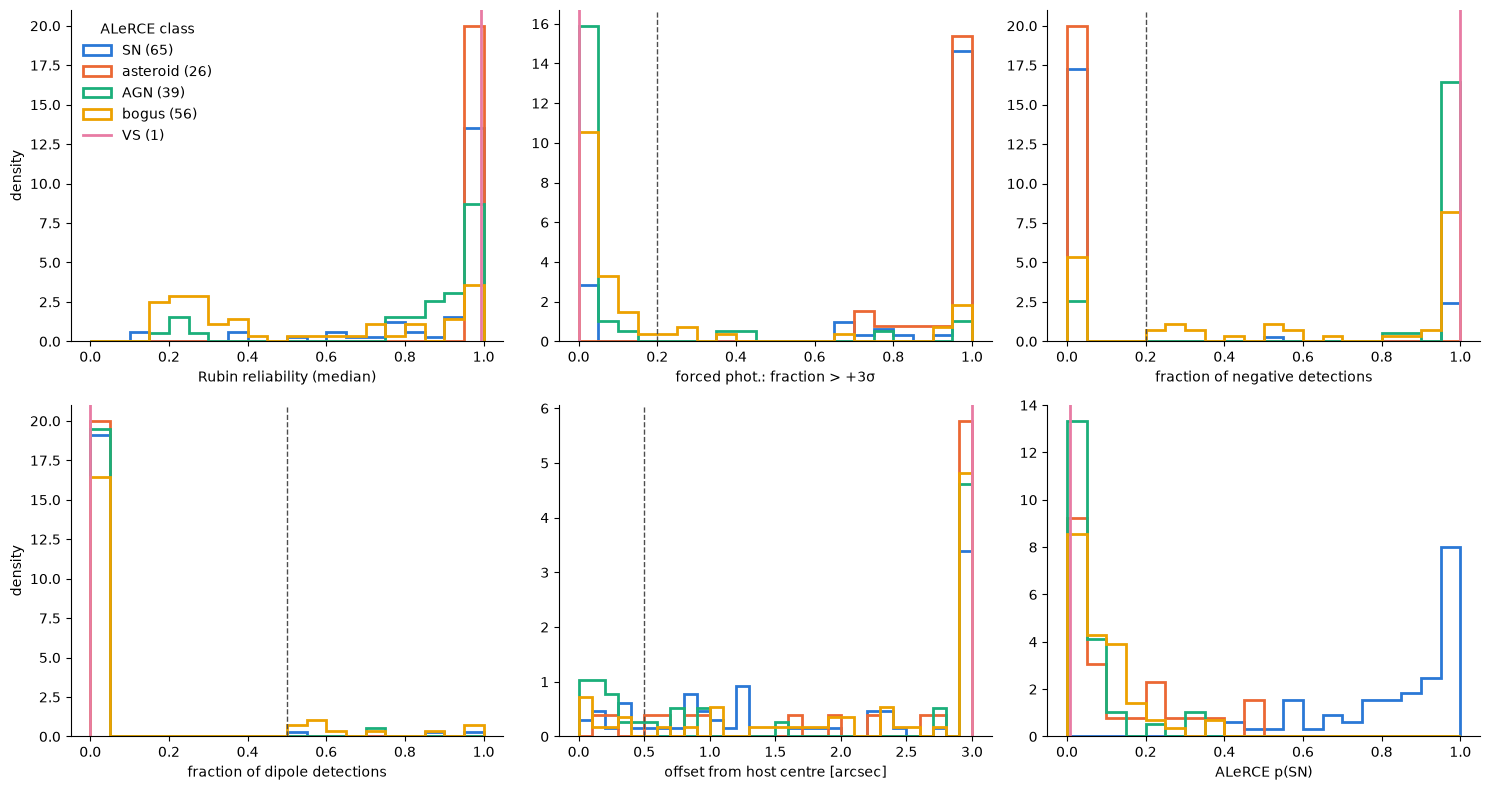

In [38]:
class_order = ["SN", "asteroid", "AGN", "bogus", "VS"]
class_color = {"SN": "#2a78d6", "asteroid": "#eb6834", "AGN": "#1baf7a", "bogus": "#eda100", "VS": "#e87ba4"}
panels = [
    ("med_rel",          np.linspace(0, 1, 21),  None,  "Rubin reliability (median)"),
    ("fp_frac_pos3",     np.linspace(0, 1, 21),  0.2,   "forced phot.: fraction > +3σ"),
    ("frac_neg",         np.linspace(0, 1, 21),  0.2,   "fraction of negative detections"),
    ("frac_dipole",      np.linspace(0, 1, 21),  0.5,   "fraction of dipole detections"),
    ("separationArcsec", np.linspace(0, 3, 31),  0.5,   "offset from host centre [arcsec]"),
    ("p_SN",             np.linspace(0, 1, 21),  None,  "ALeRCE p(SN)"),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, bins, thr, label) in zip(axes.flat, panels):
    for c in class_order:
        x = feat.loc[feat["alerce_class"] == c, col].dropna().clip(bins[0], bins[-1])
        if len(x) > 1:
            ax.hist(x, bins=bins, histtype="step", lw=2, density=True, color=class_color[c], label=f"{c} ({len(x)})")
        elif len(x) == 1:      # a histogram of one value is meaningless: mark it instead
            ax.axvline(x.iloc[0], color=class_color[c], lw=2, label=f"{c} (1)")
    if thr is not None:
        ax.axvline(thr, ls="--", color="0.3", lw=1)
    ax.set_xlabel(label)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_ylabel("density"); axes[1, 0].set_ylabel("density")
axes[0, 0].legend(title="ALeRCE class", frameon=False)
plt.tight_layout()
plt.show()

---
## 5. Hard vetoes: what is *certainly* not a SN

Each rule removes one kind of contaminant for a clear physical reason. Thresholds are deliberately
**conservative**, because a veto should essentially never remove a real SN.

| Veto | Rule | Why |
|---|---|---|
| `single_night` | `n_nights < 2` | Detected on one night only: we cannot tell a SN from an artefact or a moving object. (Not "certainly not a SN", but unusable for now; it can come back with more data.) |
| `bogus` | `max_rel < 0.3` **and** `fp_frac_pos3 < 0.2` | Rubin never considered **any** detection reliable **and** forced photometry shows no persistent flux. Two independent tests agree it is an artefact. |
| `variable` | `0.2 ≤ frac_neg ≤ 0.8` **or** (`fp_frac_neg3 > 0.2` **and** `fp_frac_pos3 > 0.2`) | The flux goes **both above and below** the template level. A SN only adds flux after explosion, so a source oscillating around the template is variable (AGN, variable star) or a systematic subtraction problem. |
| `dipole` | `frac_dipole > 0.5` | Most detections are dipoles: science/template misalignment on a bright compact source (galaxy nucleus, star). |
| `agn_host` | `separationArcsec < 0.5` **and** `W1−W2 ≥ 0.8` | Transient on the nucleus of a galaxy that is an AGN by its infrared colour. |
| `agn_like` | `separationArcsec < 0.3` **and** `p_AGN > 0.5` **and** `fp_frac_pos3 < 0.5` **and** `frac_neg < 0.8` | Nuclear, the stamp looks like an AGN, and the flux is not persistently there. A nuclear position **alone** is not enough, because nuclear SNe and TDEs exist. Objects with *only* negative flux are excluded from this veto (see below): an AGN goes up *and* down. |
| `star` | Gaia counterpart < 1″ with `p(star) > 0.9` | Stellar flare / variable star. |

**What we do *not* veto (and why):**
* **The ALeRCE label by itself** (bogus/asteroid/AGN). It is one stamp of the first alert, so it enters the score instead.
* **Objects with *only* negative flux** (`frac_neg > 0.8`). In the 1000-candidate run, vetoing them removed e.g.
  TNS 2025rha: a SN from 2025 that is **in the template image** and is now fading, so every difference is negative.
  That is still a SN (an old one). Its score is low anyway (no positive persistent flux).
* **The luminosity.** Vetoing `M > −14` or `M < −23` removed 22 objects in the first run, but almost all had their
  redshift from a "host" that Sherlock associated at **40–250″**: a big **foreground** galaxy, not the real host.
  It even removed TNS 2026euu (score 0.96). So the luminosity is only a **flag** (`lum_flag`): "if this host is
  right, the transient is too faint/bright for a SN, so check the host association". This is useful for the
  host-matching step itself.

In [39]:
vetoes = {
    "single_night":  feat["n_nights"] < 2,
    "bogus":         (feat["max_rel"] < 0.3) & (feat["fp_frac_pos3"].fillna(0) < 0.2),
    "variable":      feat["frac_neg"].between(0.2, 0.8)
                     | ((feat["fp_frac_neg3"].fillna(0) > 0.2) & (feat["fp_frac_pos3"].fillna(0) > 0.2)),
    "dipole":        feat["frac_dipole"] > 0.5,
    "agn_host":      (feat["separationArcsec"] < 0.5) & (feat["w12"] >= 0.8),
    "agn_like":      (feat["separationArcsec"] < 0.3) & (feat["p_AGN"] > 0.5)
                     & (feat["fp_frac_pos3"].fillna(0) < 0.5) & (feat["frac_neg"] < 0.8),
    "star":          (feat["gaia_dist"] < 1) & (feat["gaia_pstar"] > 0.9),
}
V = pd.DataFrame(vetoes).fillna(False).astype(bool)   # missing information never triggers a veto
feat["veto_reason"] = V.apply(lambda r: ",".join(V.columns[r.values]), axis=1)
feat["vetoed"] = V.any(axis=1)

# not a veto, a warning for the host matching (see the markdown above)
feat["lum_flag"] = np.select([feat["abs_mag"] > -14, feat["abs_mag"] < -23],
                             ["too_faint_for_host_z", "too_bright_for_host_z"], default="")

# how many objects each veto removes, split by ALeRCE class (an object can fail more than one veto)
summary = V.groupby(feat["alerce_class"]).sum().T
summary["total"] = summary.sum(axis=1)
print("Objects failing each veto:")
display(summary)
print(f"Survivors: {(~feat['vetoed']).sum()} of {len(feat)}")
print("Luminosity flags (not vetoed):", feat["lum_flag"].value_counts().to_dict())
pd.crosstab(feat["alerce_class"], feat["vetoed"].map({False: "kept", True: "rejected"}), margins=True)

Objects failing each veto:


alerce_class,AGN,SN,VS,asteroid,bogus,total
single_night,0,3,0,0,7,10
bogus,1,1,0,0,6,8
variable,0,1,0,0,15,16
dipole,1,2,0,0,9,12
agn_host,0,0,0,0,0,0
agn_like,1,0,0,0,0,1
star,1,0,1,0,0,2


Survivors: 155 of 187
Luminosity flags (not vetoed): {'': 159, 'too_faint_for_host_z': 28}


vetoed,kept,rejected,All
alerce_class,,,
AGN,36,3,39
SN,59,6,65
VS,0,1,1
asteroid,26,0,26
bogus,34,22,56
All,155,32,187


---
## 6. SN score

For every object we combine the evidence into a score between 0 and 1. Each term is already between 0 and 1:

| Term | Weight | SN-like when... |
|---|---|---|
| `p_SN` (ALeRCE, any ranking) | 0.25 | the stamp looks like a SN |
| `med_rel` (Rubin reliability) | 0.20 | Rubin thinks the detections are real |
| `fp_frac_pos3` | 0.25 | the flux is persistently there |
| `1 − frac_neg` | 0.10 | the flux is only positive |
| `offset` = min(separation / 0.5″, 1) | 0.10 | the transient is not on the nucleus |
| `min(n_bands, 3) / 3` | 0.10 | detected in several filters (real astrophysical source, colour information) |

The weights are a **choice**, not a fit (we have no labelled training set yet). The two independent "is it real and
persistent?" tests (Rubin reliability + forced photometry) and the "does it look like a SN?" test (ALeRCE) carry most
of the weight; the rest are tie-breakers. Missing values get a neutral 0.5.

*Note:* an earlier version also had a light-curve **smoothness** term (how often the flux changes direction). We removed
it: with ≤ 3 weeks of data most objects have only a few nights per band, too few for a meaningful light-curve shape
test. Its 5 % weight went to the multi-band term; in the 1000-candidate run this moved only 11 objects down one tier.

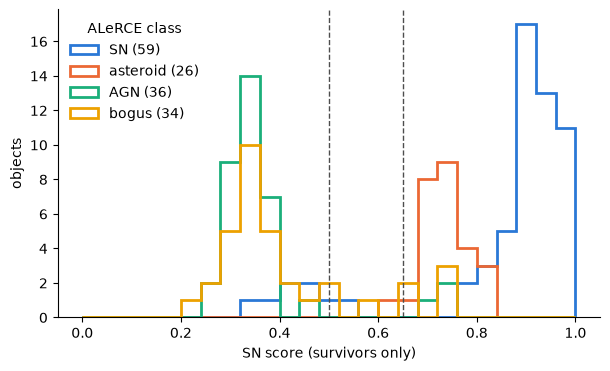

In [40]:
weights = {"p_SN": 0.25, "med_rel": 0.20, "fp_frac_pos3": 0.25, "positive": 0.10,
           "offset": 0.10, "multiband": 0.10}
terms = pd.DataFrame({
    "p_SN":         feat["p_SN"],
    "med_rel":      feat["med_rel"],
    "fp_frac_pos3": feat["fp_frac_pos3"],
    "positive":     1 - feat["frac_neg"],
    "offset":       (feat["separationArcsec"] / 0.5).clip(upper=1),
    "multiband":    feat["n_bands"].clip(upper=3) / 3,
}).fillna(0.5)
feat["sn_score"] = sum(w * terms[k] for k, w in weights.items())

fig, ax = plt.subplots(figsize=(7, 4))
for c in class_order:
    x = feat.loc[(feat["alerce_class"] == c) & ~feat["vetoed"], "sn_score"]
    if len(x):
        ax.hist(x, bins=np.linspace(0, 1, 26), histtype="step", lw=2, color=class_color[c], label=f"{c} ({len(x)})")
ax.axvline(0.5, ls="--", color="0.3", lw=1); ax.axvline(0.65, ls="--", color="0.3", lw=1)
ax.set_xlabel("SN score (survivors only)"); ax.set_ylabel("objects")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="ALeRCE class", frameon=False)
plt.show()

---
## 7. Tiers

| Tier | Rule | Meaning |
|---|---|---|
| **Gold** | no veto, ALeRCE top class = SN, score ≥ 0.65 | both brokers agree and every test supports it |
| **Silver** | no veto, score ≥ 0.5 | strong evidence, but ALeRCE disagrees or one test is weak |
| **Bronze** | no veto, score < 0.5 | nothing proves it is not a SN, but the evidence is weak: needs a visual check |
| **Rejected** | at least one veto | see `veto_reason` |

In [41]:
feat["tier"] = np.select(
    [feat["vetoed"],
     (feat["alerce_class"] == "SN") & (feat["sn_score"] >= 0.65),
     feat["sn_score"] >= 0.5],
    ["Rejected", "Gold", "Silver"], default="Bronze")

tier_order = ["Gold", "Silver", "Bronze", "Rejected"]
pd.crosstab(feat["alerce_class"], feat["tier"], margins=True).reindex(columns=tier_order + ["All"], fill_value=0)

tier,Gold,Silver,Bronze,Rejected,All
alerce_class,,,,,
AGN,0,3,33,3,39
SN,51,1,7,6,65
VS,0,0,0,1,1
asteroid,0,26,0,0,26
bogus,0,6,28,22,56
All,51,36,68,32,187


---
## 8. Sanity checks

### 8.1 TNS
Objects with a **spectroscopic** TNS classification are our ground truth. Every TNS-classified SN that ends in
"Rejected" is a veto that was too aggressive, so the list below should be (almost) empty. When the sample is
selected with a TNS condition (see the configuration), **every** object is a confirmed SN, and this check measures
directly how safe the vetoes are.

In the 1000-candidate run, the only spectroscopically classified object (SN Ia 2026ctw) was labelled "asteroid"
by ALeRCE but survived every veto and ended in **Silver**: a good example of why we do not veto on the ALeRCE label.

**Test on all 187 spectroscopically classified SNe** (`crossmatch_tns.type LIKE 'SN%'`, October 2026):
* Lasair matches TNS **by position**, so many of these "SNe" are **old** (2019–2025) and the current Rubin alerts
  are *not* the SN itself: they are the old SN fading out of the template (only negative flux), residuals, or host
  variability. Most of the rejections were of this kind, and that is correct behaviour for our purpose: those alerts
  are not a new SN.
* For the SNe discovered in **2026** (the ones actually seen by these alerts), 51 of 58 survived. 3 of the 7 rejected
  were `single_night` (not enough data yet, not a wrong decision); the other 4 failed `dipole`/`variable`.
* This test showed that `agn_like` also removed nuclear old SNe with only negative flux, so the condition
  `frac_neg < 0.8` was added to it.

In [42]:
if "tns_type" in feat:
    is_sn = feat["tns_type"].fillna("").str.startswith("SN")
    print(f"TNS-classified SNe: {is_sn.sum()}, of which rejected: {(is_sn & feat['vetoed']).sum()}")
    display(feat.loc[is_sn, ["tns_name", "tns_type", "alerce_class", "sn_score", "tier", "veto_reason"]])
pd.crosstab(feat["tns_name"].notna().map({True: "in TNS", False: "not in TNS"}), feat["tier"]
            ).reindex(columns=tier_order, fill_value=0)

TNS-classified SNe: 187, of which rejected: 32


,tns_name,tns_type,alerce_class,sn_score,tier,veto_reason
oid,,,,,,
170019717277810735,2026ctw,SN Ia,asteroid,0.679351,Silver,
170028486191218743,2026qrh,SN Ia,AGN,0.393099,Rejected,"dipole,agn_like"
170028500610711681,2024xom,SN Ia,bogus,0.284110,Bronze,
170028510695916335,2025mbp,SN Ia,AGN,0.366401,Bronze,
170028521695477812,2025aluu,SN II,AGN,0.727646,Silver,
...,...,...,...,...,...,...
313994139532263447,2026eqf,SN IIn,SN,0.991565,Gold,
313998569623257167,2025alrj,SN II,bogus,0.673090,Silver,
313998569751183527,2022and,SN II,bogus,0.288144,Bronze,


tier,Gold,Silver,Bronze,Rejected
tns_name,,,,
in TNS,39,23,68,30
not in TNS,12,13,0,2


### 8.2 Light curves: does each tier look like what it should?
Difference-image flux (positive detections filled, negative detections open) for the best-scored objects of each
tier. Gold/Silver should show positive, steady or rising/falling light curves; Rejected objects should show negative
or noisy points. Looking at the stamps of a few objects in the ALeRCE explorer (`https://alerce.online/object/<oid>`)
or in Lasair is the final check.

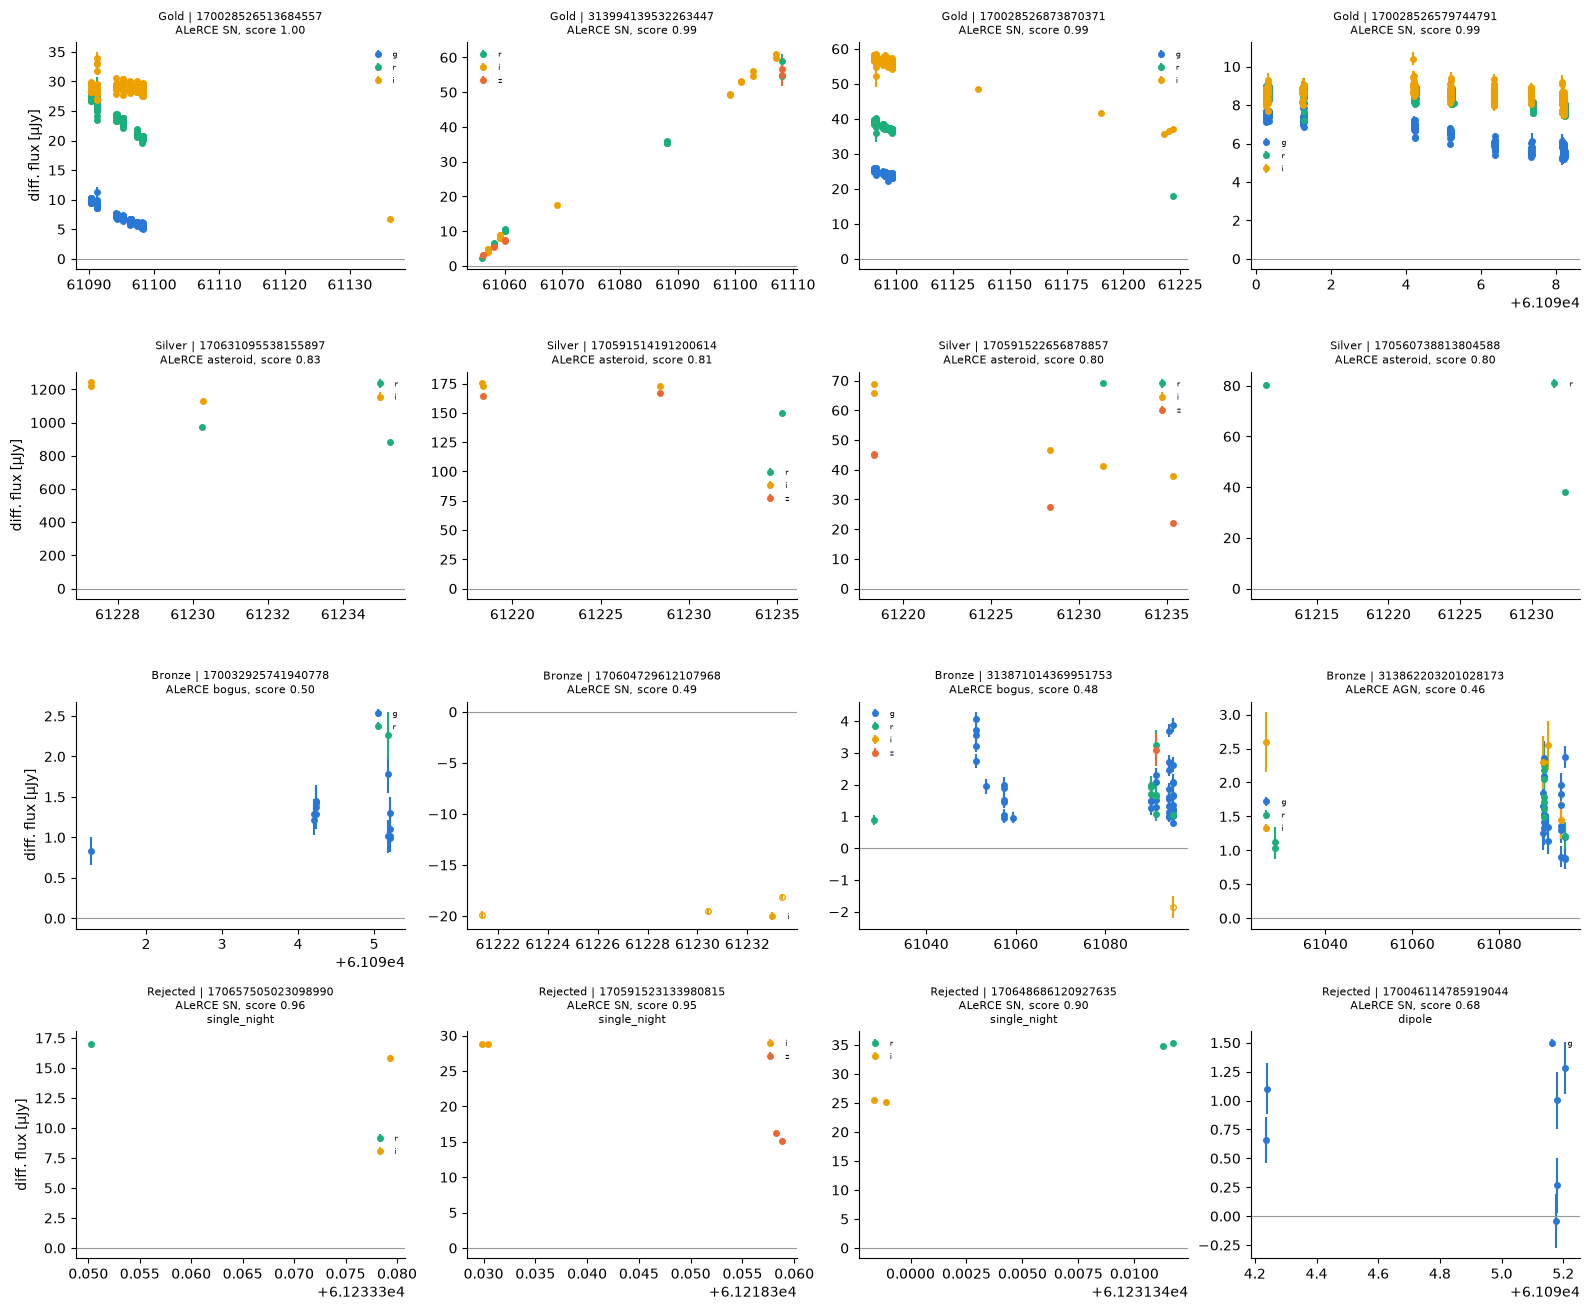

In [43]:
band_names = {1: "g", 2: "r", 3: "i", 4: "z", 5: "y", 6: "u"}
band_color = {1: "#2a78d6", 2: "#1baf7a", 3: "#eda100", 4: "#eb6834", 5: "#e87ba4", 6: "#6a4c93"}
tiers_present = [t for t in tier_order if (feat["tier"] == t).any()]
n_show = 4
fig, axes = plt.subplots(len(tiers_present), n_show, figsize=(16, 3.3 * len(tiers_present)), squeeze=False)
for row, tier in zip(axes, tiers_present):
    sample = feat[feat["tier"] == tier].sort_values("sn_score", ascending=False).head(n_show)
    for ax in row[len(sample):]:
        ax.axis("off")
    for ax, (oid, r) in zip(row, sample.iterrows()):
        d = det[det["oid"] == oid]
        for b, db in d.groupby("band"):
            for neg, fill in [(False, band_color[b]), (True, "none")]:
                x = db[db["isnegative"] == neg]
                ax.errorbar(x["mjd"], x["psfflux"] / 1e3, x["psffluxerr"] / 1e3, fmt="o", ms=4,
                            color=band_color[b], mfc=fill, label=band_names[b] if not neg else None)
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_title(f"{tier} | {oid}\nALeRCE {r['alerce_class']}, score {r['sn_score']:.2f}"
                     + (f"\n{r['veto_reason']}" if r["veto_reason"] else ""), fontsize=8)
        ax.legend(fontsize=6, frameon=False)
        ax.spines[["top", "right"]].set_visible(False)
    row[0].set_ylabel("diff. flux [µJy]")
plt.tight_layout()
plt.show()

---
## 9. Export
The ranked table (one row per object, with all features, `veto_reason`, `sn_score` and `tier`) is the input for the
host-matching step (`LSDB_matching.ipynb` / DELIGHT). Rejected objects are kept in the file so that the decision can
be audited or the thresholds changed later.

In [44]:
out_cols = ["ra", "decl", "tier", "sn_score", "veto_reason", "alerce_class", "p_SN", "p_AGN", "p_bogus",
            "n_nights", "n_bands", "med_rel", "fp_frac_pos3", "frac_neg", "frac_dipole",
            "separationArcsec", "physical_separation_kpc", "z_best", "peak_mag", "abs_mag", "lum_flag", "w12",
            "catalogue_table_name", "tns_name", "tns_type"]
tier_rank = {t: i for i, t in enumerate(tier_order)}
ranked = (feat[[c for c in out_cols if c in feat]]
          .assign(_rank=feat["tier"].map(tier_rank))
          .sort_values(["_rank", "sn_score"], ascending=[True, False])
          .drop(columns="_rank"))
ranked.to_csv("sn_candidates_ranked.csv", index_label="oid")
print(ranked["tier"].value_counts().reindex(tier_order, fill_value=0))
ranked.head(20)

tier
Gold        51
Silver      36
Bronze      68
Rejected    32
Name: count, dtype: int64


,ra,decl,tier,sn_score,veto_reason,alerce_class,p_SN,p_AGN,p_bogus,n_nights,n_bands,med_rel,fp_frac_pos3,frac_neg,frac_dipole,separationArcsec,physical_separation_kpc,z_best,peak_mag,abs_mag,lum_flag,w12,catalogue_table_name,tns_name,tns_type
oid,,,,,,,,,,,,,,,,,,,,,,,,,
170028526513684557,187.020189,6.967841,Gold,0.995449,,SN,0.987341,0.004666,0.001505,8,3,0.999852,0.994575,0.0,0.0,4.260,6.197,0.076798,20.071632,-17.708410,,NaN,NED/SDSS/PS1/DESI/2MASS,2026asx,SN I
313994139532263447,53.251363,-27.861039,Gold,0.991565,,SN,0.972766,0.012203,0.003978,12,3,0.991866,1.000000,0.0,0.0,1.841,4.715,0.146400,19.438410,-19.841103,,NaN,NED/MILLIQUAS/DESI,2026eqf,SN IIn
170028526873870371,186.808234,8.482416,Gold,0.990156,,SN,0.962750,0.002660,0.002428,12,3,1.000000,0.997872,0.0,0.0,0.542,NaN,0.268986,19.481945,-21.270470,,NaN,SDSS/PS1/DESI,2025ahkl,SN IIn
170028526579744791,185.043932,7.798861,Gold,0.988985,,SN,0.978701,0.008158,0.001482,7,3,0.987341,0.987365,0.0,0.0,1.684,NaN,0.280344,21.356503,-19.498571,,NaN,SDSS/PS1/DESI,2026fgq,SN I
170028526712914004,185.547823,7.747500,Gold,0.980160,,SN,0.949448,0.016772,0.002871,7,3,0.972919,0.992857,0.0,0.0,3.710,10.918,0.135493,21.107359,-17.989230,,NaN,NED-D/SDSS/DESI/PS1,2026ewl,SN Ia
170411112000913487,151.163533,2.507448,Gold,0.977670,,SN,0.947267,0.019826,0.002577,14,5,0.999999,0.963415,0.0,0.0,2.449,NaN,NaN,19.647713,NaN,,NaN,NED/DESI/PS1,2026mza,SN Ia
170644234890118086,292.406394,-19.597528,Gold,0.963718,,SN,0.988216,0.003544,0.001228,2,2,0.999989,1.000000,0.0,0.0,3.993,NaN,NaN,20.131756,NaN,,NaN,PS1/2MASS,NaN,SN Ia
170587105200701579,329.932686,-20.022330,Gold,0.963238,,SN,0.986341,0.002982,0.002548,4,2,0.999931,1.000000,0.0,0.0,0.981,NaN,NaN,20.704296,NaN,,0.509,PS1/DESI,NaN,SN Ia
170591521764016554,309.294987,-26.191632,Gold,0.961814,,SN,0.980587,0.003699,0.003216,2,2,1.000000,1.000000,0.0,0.0,2.266,NaN,NaN,19.706144,NaN,,NaN,DESI/PS1/2MASS,2026llc,SN Ia


---
## 10. Limitations and next steps
* **Short baseline.** All objects have ≤ ~3 weeks of data, so we cannot yet use the light-curve shape (rise time,
  decline rate, colour evolution). With a few more weeks of data a light-curve shape test can be added back, and
  `n_nights` and `fp_frac_pos3` become more powerful. ALeRCE may also start publishing its light-curve classifier for
  LSST (today `lc_classifier_BHRF_*` exists only for ZTF, `tid = 0`).
* **Weights and thresholds are not fitted.** With the current configuration (all spectroscopically classified SNe)
  section 8.1 measures how many real SNe each veto loses; restrict it to the SNe discovered this season to tune the
  vetoes that remove them.
* **Redshifts** exist for only a few percent of the hosts, and some belong to a wrong (foreground) host. Once DELIGHT
  gives the correct host and a photo-z, the luminosity test (−14 > M > −23) can become a real veto.
* **Nuclear transients.** Many Lasair "SN" sit < 0.5″ from the host centre. Without extra information they stay in
  Bronze/Silver. They could be AGN flares, TDEs or nuclear SNe; the host matching will at least tell us the host.